# Retail sales: a CRISP-DM walkthrough

Run cells from top to bottom. The data is fictional. First ask a question, then inspect, clean, summarize, and evaluate.

## 1. Business understanding
Which category contributes the most revenue? How does monthly revenue change? Revenue is not profit.

In [1]:
import pandas as pd
from IPython.display import Image, display
from analysis import ROOT, clean_sales, summarize_sales, run

raw = pd.read_csv(ROOT / 'data/sales.csv')
raw.head()

,transaction_id,date,category,branch,quantity,unit_price,discount
0,TX0001,2025-01-01,Stationery,Campus,1.0,12000,0.1
1,TX0002,2025-01-02,Drinks,City,3.0,18000,0.0
2,TX0003,2025-01-03,Snacks,Campus,5.0,15000,0.0
3,TX0004,2025-01-04,Stationery,City,2.0,12000,0.0
4,TX0005,2025-01-05,Drinks,Campus,4.0,18000,0.1


## 2. Data understanding
Inspect missing values before making a cleaning rule. A blank category and a blank quantity do not have the same consequences.

In [2]:
print('Shape:', raw.shape)
display(raw.dtypes.to_frame('type'))
display(raw.isna().sum().to_frame('missing'))
print('Exact duplicates:', raw.duplicated().sum())

Shape: (181, 7)


,type
transaction_id,object
date,object
category,object
branch,object
quantity,float64
unit_price,int64
discount,float64


,missing
transaction_id,0
date,0
category,1
branch,0
quantity,1
unit_price,0
discount,0


Exact duplicates: 1


## 3. Data preparation
The cleaning function keeps an Unknown category but excludes records whose revenue cannot be calculated reliably. Conflicting IDs stop the analysis.

In [3]:
clean, audit = clean_sales(raw)
display(audit)
clean.head()

{'input_rows': 181,
 'exact_duplicates_removed': 1,
 'invalid_rows_removed': 4,
 'missing_categories_filled': 1,
 'output_rows': 176}

,transaction_id,date,category,branch,quantity,unit_price,discount,revenue
0,TX0001,2025-01-01,Stationery,Campus,1,12000,0.1,10800.0
1,TX0002,2025-01-02,Drinks,City,3,18000,0.0,54000.0
2,TX0003,2025-01-03,Snacks,Campus,5,15000,0.0,75000.0
3,TX0004,2025-01-04,Stationery,City,2,12000,0.0,24000.0
4,TX0005,2025-01-05,Drinks,Campus,4,18000,0.1,64800.0


## 4. Modeling through descriptive aggregation
No predictive model is needed for these questions. Inspect the revenue formula for the first transaction, then group the cleaned rows.

In [4]:
first = clean.iloc[0]
print(first['quantity'] * first['unit_price'] * (1 - first['discount']))
summary, category, monthly = summarize_sales(clean)
display(summary)
display(category.to_frame())
display(monthly.to_frame())

10800.0


{'transactions': 176,
 'total_revenue_idr': 7750500.0,
 'average_transaction_value_idr': 44036.93,
 'top_category': 'Drinks'}

,revenue
category,
Drinks,2979000.0
Snacks,2587500.0
Stationery,2094000.0
Unknown,90000.0


,revenue
date,
2025-01,1317300.0
2025-02,1198200.0
2025-03,1359300.0
2025-04,1243200.0
2025-05,1329300.0
2025-06,1303200.0


## 5. Evaluation
Every valid transaction should contribute exactly once. Both sets of grouped totals must reconcile with the overall total.

In [5]:
assert abs(category.sum() - clean.revenue.sum()) < 0.01
assert abs(monthly.sum() - clean.revenue.sum()) < 0.01
assert clean.transaction_id.is_unique
print('Grouped totals reconcile with the cleaned data.')

Grouped totals reconcile with the cleaned data.


## 6. Deployment as a report
The script saves tables, a chart, and written findings. In a real project, review excluded source records before presenting the report.

{
  "cleaning": {
    "input_rows": 181,
    "exact_duplicates_removed": 1,
    "invalid_rows_removed": 4,
    "missing_categories_filled": 1,
    "output_rows": 176
  },
  "results": {
    "transactions": 176,
    "total_revenue_idr": 7750500.0,
    "average_transaction_value_idr": 44036.93,
    "top_category": "Drinks"
  }
}


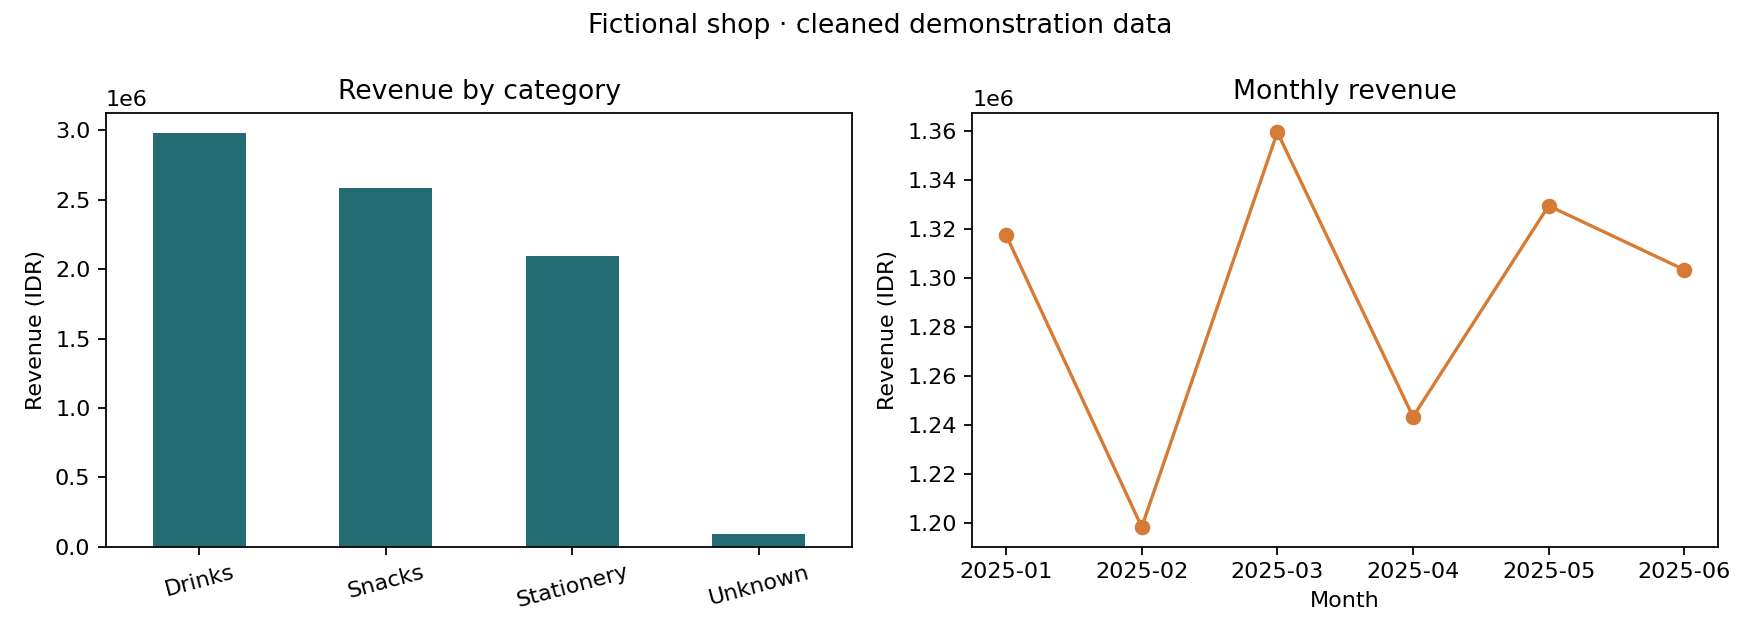

# Sales findings

These results describe the included synthetic data, not a real shop.

- Valid transactions: 176
- Revenue after discounts: IDR 7,750,500
- Average transaction: IDR 44,037
- Largest category by revenue: Drinks
- Removed: 1 exact duplicate and 4 invalid rows.

Revenue does not measure profit: product costs are unavailable. Check source records for removed transactions before using this process in real reporting.



In [6]:
_ = run()
display(Image(filename=str(ROOT / 'outputs/sales_overview.png')))
print((ROOT / 'outputs/report.md').read_text())

## Practice
Add a branch-level revenue table. Explain why comparing the final partial month with a full month could mislead someone. Return to data understanding if the comparison needs a different time period.